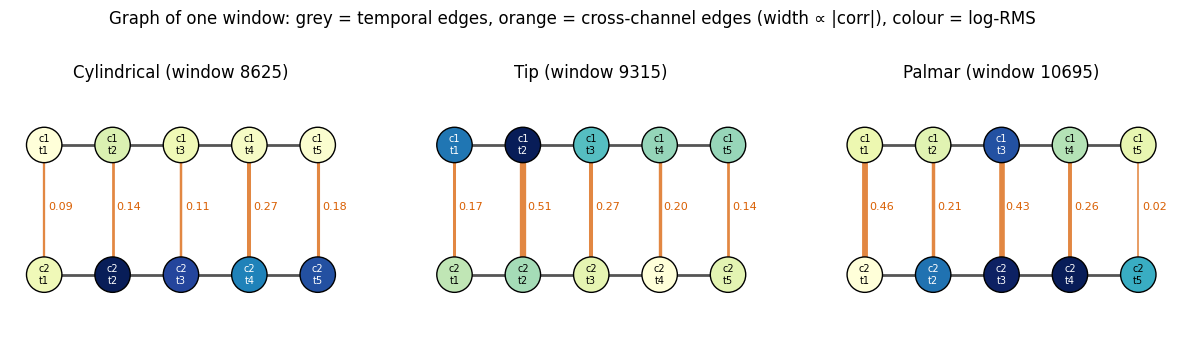

In [14]:
# (A) visualise the graph of one real window ============
def draw_graph(i, ax):
    G, E = D["G"][i], D["E"][i]
    col = G[:, :, 1]
    vmin, vmax = col.min(), col.max()
    for t in range(K_SEG):
        ax.plot([t, t], [0, 1], lw=1 + 7 * E[t], color="#d95f02", alpha=.75, zorder=1)
        ax.text(t + .06, .5, f"{E[t]:.2f}", fontsize=8, color="#d95f02")
    for c in range(2):
        y = 1 - c
        ax.plot(range(K_SEG), [y] * K_SEG, color="#555", lw=2, zorder=1)
        ax.scatter(range(K_SEG), [y] * K_SEG, c=col[c], cmap="YlGnBu", vmin=vmin, vmax=vmax, s=650, edgecolor="k", zorder=3)
        for t in range(K_SEG): ax.text(t, y, f"c{c+1}\nt{t+1}", ha="center", va="center", fontsize=7, zorder=4, color="white" if (col[c][t]-vmin)/(vmax-vmin+1e-9) > .55 else "black")
    ax.set_xlim(-.5, K_SEG - .5); ax.set_ylim(-.45, 1.45); ax.axis("off")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, c in zip(axes, [0, 1, 3]):
    i = np.where(D["y"] == c)[0][len(np.where(D["y"] == c)[0]) // 2]; draw_graph(i, ax); ax.set_title(f"{CLASS_NAMES[c]} (window {i})")
fig.suptitle("Graph of one window: grey = temporal edges, orange = cross-channel edges (width ∝ |corr|), colour = log-RMS", y=1.12); plt.show()

This graph represents EMG signals as a graph structure. Each node represents a channel at a specific time step. Grey edges capture temporal relationships between consecutive time steps, while orange edges represent cross-channel relationships based on correlation. The thickness of orange edges indicates correlation strength, and node colours represent log-RMS values. This graph representation helps the GNN learn temporal and cross-channel relationships for hand movement classification.

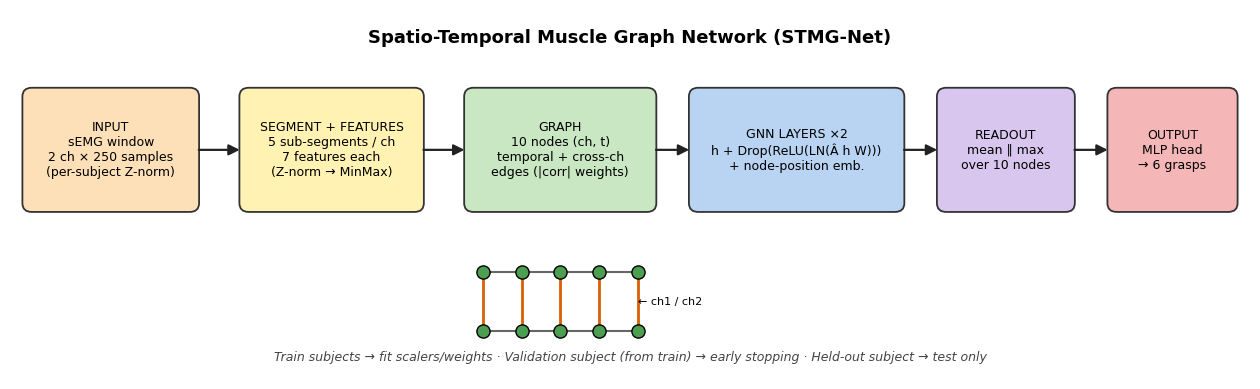

In [15]:
#  (B) architecture diagram ============
fig, ax = plt.subplots(figsize=(16, 4.8)); ax.set_xlim(0, 16); ax.set_ylim(0, 5); ax.axis("off")
def box(x, y, w, h, txt, fc, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=fc, ec="#333", lw=1.3))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs)
def arrow(x1, x2, y=3.1): ax.add_patch(FancyArrowPatch((x1, y), (x2, y), arrowstyle="-|>", mutation_scale=16, lw=1.6, color="#222"))
box(0.2, 2.3, 2.2, 1.6, "INPUT\nsEMG window\n2 ch × 250 samples\n(per-subject Z-norm)", "#fde0b8")
box(3.0, 2.3, 2.3, 1.6, "SEGMENT + FEATURES\n5 sub-segments / ch\n7 features each\n(Z-norm → MinMax)", "#fff2b3")
box(5.9, 2.3, 2.4, 1.6, "GRAPH\n10 nodes (ch, t)\ntemporal + cross-ch\nedges (|corr| weights)", "#c9e7c3")
box(8.8, 2.3, 2.7, 1.6, "GNN LAYERS ×2\nh + Drop(ReLU(LN(Â h W)))\n+ node-position emb.", "#b9d3f2")
box(12.0, 2.3, 1.7, 1.6, "READOUT\nmean ‖ max\nover 10 nodes", "#d9c6ee")
box(14.2, 2.3, 1.6, 1.6, "OUTPUT\nMLP head\n→ 6 grasps", "#f4b6b6")
for a, b in [(2.4, 3.0), (5.3, 5.9), (8.3, 8.8), (11.5, 12.0), (13.7, 14.2)]: arrow(a, b)
for c in range(2):
    xs = 6.1 + np.arange(5) * 0.5; ys = np.full(5, 1.45 - c * 0.8)
    ax.plot(xs, ys, color="#666", lw=1.5)
    ax.scatter(xs, ys, s=90, c="#4c9f50", edgecolor="k", zorder=3)
for x in 6.1 + np.arange(5) * 0.5: ax.plot([x, x], [0.65, 1.45], color="#d95f02", lw=2)
ax.text(8.1, 1.05, "← ch1 / ch2", fontsize=8, va="center")
ax.text(8.0, 4.55, "Spatio-Temporal Muscle Graph Network (STMG-Net)", ha="center", fontsize=13, weight="bold")
ax.text(8.0, 0.25, "Train subjects → fit scalers/weights · Validation subject (from train) → early stopping · Held-out subject → test only", ha="center", fontsize=9, style="italic", color="#444")
plt.show()

Our proposed STMG-Net architecture takes two-channel sEMG signals as input. Each input window contains 250 samples per channel. The signals are divided into five sub-segments, and seven features are extracted from each segment. These features are used to construct a graph containing ten nodes, representing two channels across five time segments. Temporal and cross-channel edges capture the relationships between nodes. The graph is then processed through two GNN layers to learn spatial and temporal muscle activity patterns. Mean and max pooling aggregate the node representations into a graph-level representation. Finally, an MLP classifier predicts one of six hand-grasp classes. We use subject-independent training and evaluation to assess the model's ability to generalize to unseen subjects.